#1.Cleaning

In [1]:
import numpy as np
import pandas as pd

In [2]:
data = pd.read_csv("Social_media_impact_on_life.csv")

In [3]:
data.shape

(4500, 16)

In [4]:
data.info

<bound method DataFrame.info of        Student_ID  Age  Gender Academic_Level Primary_Platform  \
0     STU_2024000   19  Female  Undergraduate         Snapchat   
1     STU_2024001   19  Female  Undergraduate        Instagram   
2     STU_2024002   17  Female    High School           TikTok   
3     STU_2024003   16  Female    High School          YouTube   
4     STU_2024004   17    Male    High School         LinkedIn   
...           ...  ...     ...            ...              ...   
4495  STU_2028495   16    Male    High School          YouTube   
4496  STU_2028496   19  Female  Undergraduate         LinkedIn   
4497  STU_2028497   19    Male  Undergraduate        Instagram   
4498  STU_2028498   16    Male    High School         LinkedIn   
4499  STU_2028499   24    Male  Undergraduate        Instagram   

      Daily_Usage_Hours  Weekend_Extra_Hours Device_Type  \
0                   7.5                  1.5  Smartphone   
1                   4.6                  1.3  Smartphon

In [6]:
data = pd.read_csv("Social_media_impact_on_life.csv")

In [9]:
string_cols = data.select_dtypes(include=['object']).columns
data[string_cols] = data[string_cols].apply(lambda x: x.str.strip())

In [11]:
data['Academic_Performance_GPA'] = data.groupby('Academic_Level')['Academic_Performance_GPA'].transform(lambda x: x.fillna(x.median()))
data['Perceived_Stress_Score'] = data['Perceived_Stress_Score'].fillna(data['Perceived_Stress_Score'].median())


In [12]:
data['Primary_Platform'] = data['Primary_Platform'].replace('X (Twitter)', 'X')


In [13]:
data['Late_Night_Usage'] = data['Late_Night_Usage'].astype(bool)
int_cols = ['Age', 'Sleep_Quality_Score', 'Mental_Health_Index']
data[int_cols] = data[int_cols].astype(int)


In [15]:
data.drop_duplicates(subset=['Student_ID'],inplace=True)

In [22]:
data.to_csv("cleaned_student_dataset.csv", index=False)

#2.Visualization

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

In [22]:
import pandas as pd
import numpy as np

In [23]:
df = pd.read_csv("cleaned_student_dataset.csv")

In [24]:
sns.set_theme(style="whitegrid")
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 12, 'axes.titlesize': 14})

In [25]:
plt.figure(figsize=(10,8))

<Figure size 1000x800 with 0 Axes>

<Figure size 1000x800 with 0 Axes>

In [26]:
numerical_cols = [
    'Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 
    'Sleep_Duration_Hours', 'Sleep_Quality_Score', 
    'Perceived_Stress_Score', 'Mental_Health_Index', 'Academic_Performance_GPA'
]
corr_matrix = df[numerical_cols].corr()

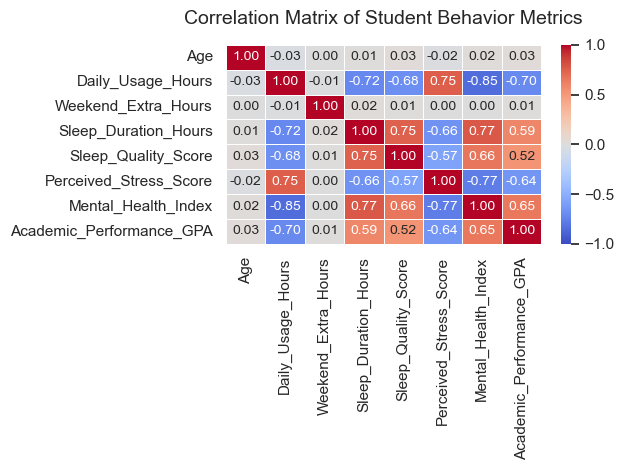

In [27]:
sns.heatmap(
    corr_matrix, 
    annot=True, 
    cmap='coolwarm', 
    fmt=".2f", 
    linewidths=0.5, 
    vmin=-1, vmax=1
)
plt.title("Correlation Matrix of Student Behavior Metrics", pad=15)
plt.tight_layout()
plt.savefig("behavior_correlation_heatmap.png", dpi=300)
plt.show()

In [28]:
plt.figure(figsize=(9,6))

<Figure size 900x600 with 0 Axes>

<Figure size 900x600 with 0 Axes>

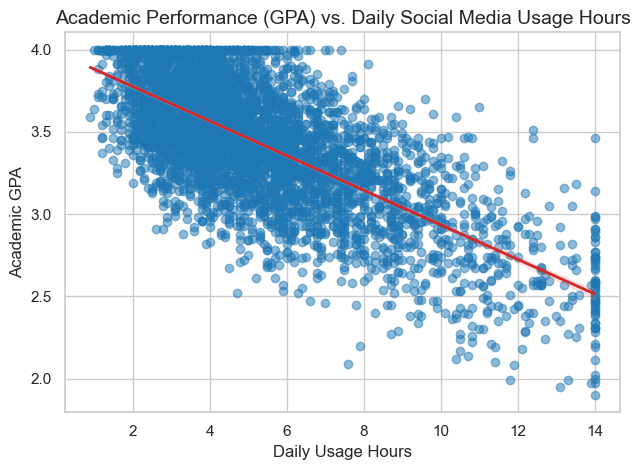

In [29]:
sns.regplot(
    data=df, 
    x='Daily_Usage_Hours', 
    y='Academic_Performance_GPA',
    scatter_kws={'alpha':0.5, 'color': '#1f77b4'}, 
    line_kws={'color': '#d62728', 'linewidth': 2}
)
plt.title("Academic Performance (GPA) vs. Daily Social Media Usage Hours")
plt.xlabel("Daily Usage Hours")
plt.ylabel("Academic GPA")
plt.tight_layout()
plt.savefig("gpa_vs_usage_regression.png", dpi=300)
plt.show()

In [30]:
plt.figure(figsize=(10,6))

<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

In [31]:
platform_order = df['Primary_Platform'].value_counts().index

C:\Users\91630\AppData\Local\Temp\ipykernel_8028\1094621000.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


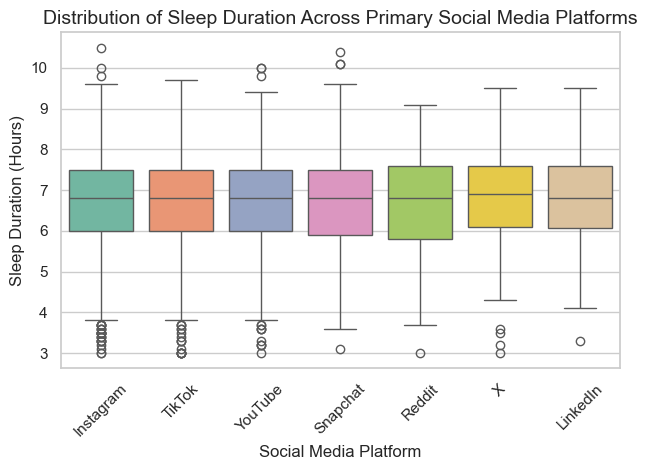

In [32]:
sns.boxplot(
    data=df, 
    x='Primary_Platform', 
    y='Sleep_Duration_Hours', 
    order=platform_order,
    palette="Set2"
)
plt.title("Distribution of Sleep Duration Across Primary Social Media Platforms")
plt.xlabel("Social Media Platform")
plt.ylabel("Sleep Duration (Hours)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("sleep_duration_by_platform.png", dpi=300)
plt.show()

#3.Prediction Models

In [33]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import mean_squared_error, r2_score, classification_report, accuracy_score


In [34]:
df = pd.read_csv("cleaned_student_dataset.csv")

In [35]:
print("--- Track 1: Running GPA Prediction Regression Model ---")

# Select independent behavioral features (X) and target numerical feature (y)
X_reg = df[['Age', 'Daily_Usage_Hours', 'Weekend_Extra_Hours', 'Sleep_Duration_Hours', 
            'Sleep_Quality_Score', 'Perceived_Stress_Score', 'Mental_Health_Index']]
y_reg = df['Academic_Performance_GPA']


--- Track 1: Running GPA Prediction Regression Model ---


In [36]:
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

In [37]:
reg_model = LinearRegression()
reg_model.fit(X_train_r, y_train_r)


LinearRegression()

In [38]:
y_pred_r = reg_model.predict(X_test_r)
rmse = np.sqrt(mean_squared_error(y_test_r, y_pred_r))
r2 = r2_score(y_test_r, y_pred_r)

In [39]:
print(f"Root Mean Squared Error (RMSE): {rmse:.3f} GPA points")
print(f"R-squared Score (Variance Explained): {r2:.3f}\n")


Root Mean Squared Error (RMSE): 0.260 GPA points
R-squared Score (Variance Explained): 0.545



In [40]:
print("--- Track 2: Running Overall_Impact Classification Model ---")

# Step A: Drop rows where target variable is missing or blank
df_clf = df.dropna(subset=['Overall_Impact'])

--- Track 2: Running Overall_Impact Classification Model ---


In [41]:
categorical_features = ['Gender', 'Academic_Level', 'Primary_Platform', 'Device_Type', 'Social_Comparison_Frequency']
df_encoded = pd.get_dummies(df_clf, columns=categorical_features, drop_first=True)


In [42]:
exclude_cols = ['Student_ID', 'Overall_Impact', 'Academic_Performance_GPA']
X_clf = df_encoded.drop(columns=[col for col in exclude_cols if col in df_encoded.columns])
y_clf = df_encoded['Overall_Impact']


In [43]:
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)


In [44]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_c)
X_test_scaled = scaler.transform(X_test_c)

In [45]:
clf_model = RandomForestClassifier(n_estimators=100, random_state=42, max_depth=6)
clf_model.fit(X_train_scaled, y_train_c)


RandomForestClassifier(max_depth=6, random_state=42)

In [46]:
y_pred_c = clf_model.predict(X_test_scaled)
accuracy = accuracy_score(y_test_c, y_pred_c)


In [48]:
print(f"Model Classification Accuracy: {accuracy * 100:.2f}%")
print("\nDetailed Classification Performance Matrix Report:")
print(classification_report(y_test_c, y_pred_c))


Model Classification Accuracy: 94.56%

Detailed Classification Performance Matrix Report:
              precision    recall  f1-score   support

  Beneficial       0.97      0.98      0.97       736
    Negative       0.90      0.82      0.86        33
     Neutral       0.83      0.79      0.81       131

    accuracy                           0.95       900
   macro avg       0.90      0.86      0.88       900
weighted avg       0.94      0.95      0.94       900



In [49]:
feature_importances = pd.Series(clf_model.feature_importances_, index=X_clf.columns).sort_values(ascending=False)
print("Top 5 Variables Driving Student Impact Outcomes:")
print(feature_importances.head(5))

Top 5 Variables Driving Student Impact Outcomes:
Perceived_Stress_Score    0.335714
Mental_Health_Index       0.263700
Daily_Usage_Hours         0.180447
Sleep_Duration_Hours      0.104386
Sleep_Quality_Score       0.073344
dtype: float64


#4.Dashboard creation

In [50]:
import pandas as pd
import numpy as np
import streamlit as st
import plotly.express as px
from sklearn.linear_model import LinearRegression

# ==========================================
# 1. INITIAL APP CONFIGURATION
# ==========================================
st.set_page_config(
    page_title="Student Behavior & Performance Dashboard",
    page_icon="🎓",
    layout="wide"
)

st.title("🎓 Student Behavior, Wellbeing & Performance Dashboard")
st.markdown("Analyse how screentime, stress, and sleep metrics interact with academic outcomes.")

# Load the cleaned dataset
@st.cache_data
def load_data():
    df = pd.read_csv("cleaned_student_dataset.csv")
    return df

df = load_data()

# ==========================================
# 2. SIDEBAR FILTER CONTROLS
# ==========================================
st.sidebar.header("🛠️ Dashboard Filters")

# Academic Level Filter
academic_levels = ["All"] + list(df['Academic_Level'].unique())
selected_level = st.sidebar.selectbox("Select Academic Level:", academic_levels)

# Primary Platform Filter
platforms = ["All"] + list(df['Primary_Platform'].unique())
selected_platform = st.sidebar.selectbox("Select Primary Social Platform:", platforms)

# Apply dynamic scoping filters to the data frame context
filtered_df = df.copy()
if selected_level != "All":
    filtered_df = filtered_df[filtered_df['Academic_Level'] == selected_level]
if selected_platform != "All":
    filtered_df = filtered_df[filtered_df['Primary_Platform'] == selected_platform]

# ==========================================
# 3. HIGH-LEVEL KPI METRICS ROW
# ==========================================
st.markdown("### 📊 Cohort At-A-Glance")
kpi1, kpi2, kpi3, kpi4 = st.columns(4)

with kpi1:
    st.metric("Total Sample Size", f"{len(filtered_df)} Students")
with kpi2:
    st.metric("Average Daily Screen Time", f"{filtered_df['Daily_Usage_Hours'].mean():.1f} Hrs")
with kpi3:
    st.metric("Mean Stress Score", f"{filtered_df['Perceived_Stress_Score'].mean():.1f} / 40")
with kpi4:
    st.metric("Average Cohort GPA", f"{filtered_df['Academic_Performance_GPA'].mean():.2f}")

st.markdown("---")

# ==========================================
# 4. INTERACTIVE GRAPHICS LAYOUT
# ==========================================
col1, col2 = st.columns(2)

with col1:
    st.markdown("#### 📉 Screen Time vs. Academic GPA Trend")
    fig_scatter = px.scatter(
        filtered_df,
        x="Daily_Usage_Hours",
        y="Academic_Performance_GPA",
        color="Gender",
        trendline="ols",
        labels={"Daily_Usage_Hours": "Daily Screen Hours", "Academic_Performance_GPA": "GPA Value"},
        color_discrete_sequence=px.colors.qualitative.Safe
    )
    st.plotly_chart(fig_scatter, use_container_width=True)

with col2:
    st.markdown("#### 🛌 Sleep Variance Distribution Across Platforms")
    fig_box = px.box(
        filtered_df,
        x="Primary_Platform",
        y="Sleep_Duration_Hours",
        color="Primary_Platform",
        labels={"Primary_Platform": "Platform App", "Sleep_Duration_Hours": "Sleep (Hours)"},
        color_discrete_sequence=px.colors.qualitative.Set2
    )
    st.plotly_chart(fig_box, use_container_width=True)

st.markdown("---")

# ==========================================
# 5. LIVE ML PREDICTION ENGINES
# ==========================================
st.markdown("### 🔮 Interactive AI Simulation: Predict Student GPA")
st.markdown("Adjust the behavioral markers below to immediately simulate a student's estimated GPA outcome in real time.")

# Train an inline lightweight operational regression engine model on backend load
X_train = df[['Age', 'Daily_Usage_Hours', 'Sleep_Duration_Hours', 'Perceived_Stress_Score']]
y_train = df['Academic_Performance_GPA']
sim_reg = LinearRegression().fit(X_train, y_train)

# Setup numerical input control grids for simulation
sim_col1, sim_col2, sim_col3, sim_col4 = st.columns(4)

with sim_col1:
    input_age = st.slider("Student Age:", int(df['Age'].min()), int(df['Age'].max()), 18)
with sim_col2:
    input_usage = st.slider("Daily Screen Time (Hours):", 0.0, 16.0, 4.5, step=0.5)
with sim_col3:
    input_sleep = st.slider("Sleep Duration (Hours):", 2.0, 12.0, 7.0, step=0.5)
with sim_col4:
    input_stress = st.slider("Perceived Stress (0-40 Scale):", 0, 40, 15)

# Calculate live array vector prediction point
user_input = np.array([[input_age, input_usage, input_sleep, input_stress]])
predicted_gpa = sim_reg.predict(user_input)[0]

# Bound the display prediction within realistic absolute mathematical scaling limits
predicted_gpa = max(0.00, min(4.00, predicted_gpa))

# Render Simulated Outcome
st.markdown(f"#### 🎯 Predicted Academic GPA Result: `{predicted_gpa:.2f}`")
if predicted_gpa >= 3.5:
    st.success("🌟 Outcome Estimate: High Academic Achievement Profile.")
elif predicted_gpa >= 2.5:
    st.info("⚖️ Outcome Estimate: Average Cohort Performance Profile.")
else:
    st.warning("⚠️ Outcome Estimate: Elevated Behavioral Risk Profile. Academic support recommended.")


2026-10-30 16:38:33.594 
  command:

    streamlit run C:\Users\91630\anaconda3\Lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-10-30 16:38:33.594 No runtime found, using MemoryCacheStorageManager
2026-10-30 16:38:33.602 No runtime found, using MemoryCacheStorageManager
2026-10-30 16:38:33.633 Session state does not function when running a script without `streamlit run`
C:\Users\91630\anaconda3\Lib\site-packages\sklearn\base.py:493: UserWarning:

X does not have valid feature names, but LinearRegression was fitted with feature names

